In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

### Logestic Regression {perseptron also called as Single Layer Neural Network}

In [2]:
RANDOM_STATE=24
np.random.seed(RANDOM_STATE)
rng=np.random.default_rng(seed=RANDOM_STATE)
NOISE=0.2
EPOCHS=200
ALPHA=0.001 #LEARNING RATE
TEST_SIZE=0.2
N_SAMPLES=1000
params={
    'legend.fontsize':'medium',
    'figure.figuresize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',  
    'ytick.labelsize':'medium',  
    
}

In [3]:
X,y=datasets.make_moons(n_samples=N_SAMPLES,
                        shuffle=True,
                        noise=NOISE,
                        random_state=RANDOM_STATE
                       )
X[:5],y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [4]:
df=pd.DataFrame(X,columns=['A','B'])
df['Target']=y
df.head()

,A,B,Target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A       1000 non-null   float64
 1   B       1000 non-null   float64
 2   Target  1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [6]:
df.describe()

,A,B,Target
count,1000.000000,1000.000000,1000.00000
mean,0.490841,0.239025,0.50000
std,0.898951,0.540082,0.50025
min,-1.688795,-0.955280,0.00000
25%,-0.149565,-0.205090,0.00000
50%,0.500100,0.241163,0.50000
75%,1.095048,0.680394,1.00000
max,2.419113,1.612075,1.00000


In [7]:
df.Target.value_counts()

Target
0    500
1    500
Name: count, dtype: int64

<Axes: xlabel='Target', ylabel='count'>

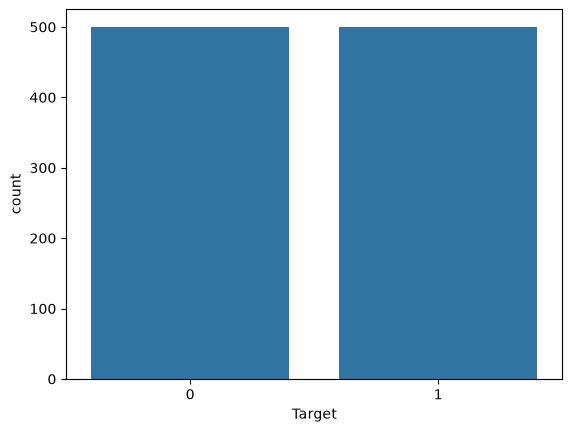

In [8]:
sns.barplot(df.Target.value_counts())

<Axes: xlabel='A', ylabel='B'>

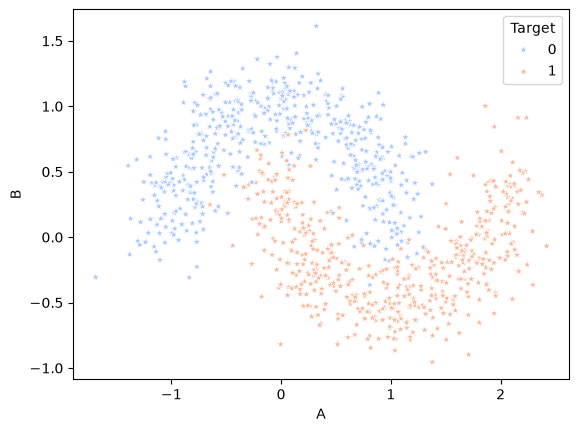

In [9]:
sns.scatterplot(df,x='A',y='B',hue='Target',palette='coolwarm',marker='*')


In [10]:
data_train, data_test= df.to_numpy()[:900], df.to_numpy()[900:]
print(data_train.shape,data_test.shape)

(900, 3) (100, 3)


In [11]:
def predict(row: np.ndarray, wgts: np.ndarray):
    '''
    row: one sample of data
    wgts: Weight of the model
    '''
    z=wgts[0]

    for i in range(len(row)-1):
        z+= wgts[i+1]* row[i] # Aggrigation function
    return 1 if z>=0 else 0 # sample activation

In [12]:
weight=np.array([0.1, 2.0, 1.0])

display(df.loc[0])
predict(df.loc[0].values,weight)

A         0.906340
B         0.902676
Target    0.000000
Name: 0, dtype: float64

1

In [13]:
rng.standard_normal(data_train.shape[1])

array([ 1.35074732,  0.34309058, -1.16299016])

In [14]:
rng.standard_normal(data_train.shape[1])

array([-0.18708582, -0.3394646 , -0.22767632])

In [15]:
rng.standard_normal(data_train.shape[1])

array([ 0.59685616, -1.27902314,  0.96665533])

In [16]:
def train_weights(train: np.ndarray, alpha: float, n_epochs: int):
    errors=[] # colledt all errors
    weights=rng.standard_normal(train.shape[1])# random generation
    m=train.shape[0] # num samples

    for epoch in range(n_epochs):
        sum_error=0.0
        for row in train:
            prediction=predict(row, weights)
            error =prediction -row[-1] 
            sum_error+=error**2
            weights[0]=weights[0]- alpha* error
            for i in range(len(row)-1):
                weights[i+1]= weights[i+1]- alpha*error *row[i]
        errors.append(sum_error/m)
        if epoch%10==0:
            print(f'Epoch {epoch:3d}: Loss={errors[-1]:4f}')
    return errors, weights

In [17]:
errors,weights=train_weights(data_train,ALPHA,EPOCHS)
display(weights)
errors

Epoch   0: Loss=0.560000
Epoch  10: Loss=0.144444
Epoch  20: Loss=0.178889
Epoch  30: Loss=0.184444
Epoch  40: Loss=0.178889
Epoch  50: Loss=0.165556
Epoch  60: Loss=0.182222
Epoch  70: Loss=0.180000
Epoch  80: Loss=0.177778
Epoch  90: Loss=0.182222
Epoch 100: Loss=0.177778
Epoch 110: Loss=0.176667
Epoch 120: Loss=0.167778
Epoch 130: Loss=0.174444
Epoch 140: Loss=0.177778
Epoch 150: Loss=0.176667
Epoch 160: Loss=0.171111
Epoch 170: Loss=0.181111
Epoch 180: Loss=0.174444
Epoch 190: Loss=0.180000


array([-0.00096069,  0.00047322, -0.0037151 ])

[np.float64(0.56),
 np.float64(0.5888888888888889),
 np.float64(0.5244444444444445),
 np.float64(0.4666666666666667),
 np.float64(0.4077777777777778),
 np.float64(0.35777777777777775),
 np.float64(0.32222222222222224),
 np.float64(0.27666666666666667),
 np.float64(0.2311111111111111),
 np.float64(0.16777777777777778),
 np.float64(0.14444444444444443),
 np.float64(0.1411111111111111),
 np.float64(0.15777777777777777),
 np.float64(0.17888888888888888),
 np.float64(0.18333333333333332),
 np.float64(0.17777777777777778),
 np.float64(0.17777777777777778),
 np.float64(0.18444444444444444),
 np.float64(0.1811111111111111),
 np.float64(0.16444444444444445),
 np.float64(0.17888888888888888),
 np.float64(0.1811111111111111),
 np.float64(0.17666666666666667),
 np.float64(0.17222222222222222),
 np.float64(0.17888888888888888),
 np.float64(0.18),
 np.float64(0.18444444444444444),
 np.float64(0.18),
 np.float64(0.17777777777777778),
 np.float64(0.18222222222222223),
 np.float64(0.18444444444444444),

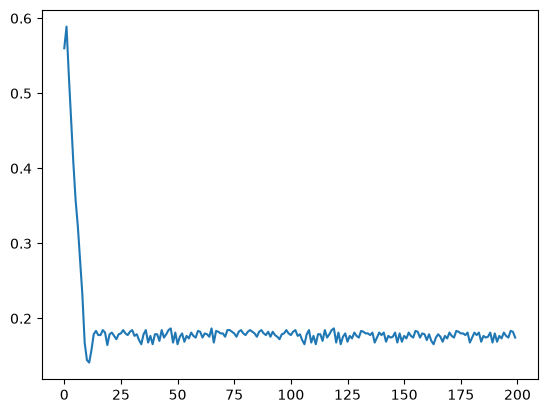

In [18]:
plt.plot(errors)

In [19]:
# def train_weights(train: np.ndarray, alpha: float, n_epochs: int):
#     errors=[] # colledt all errors
#     weights=rng.random(train.shape[1])# random generation
#     m=train.shape[0] # num samples

#     for epoch in range(n_epochs):
#         sum_error=0.0
#         for row in train:
#             prediction=predict(row, weights)
#             error =prediction -row[-1] 
#             sum_error+=error**2
#             weights[0]=weights[0]- alpha* error
#             for i in range(len(row)-1):
#                 weights[i+1]= weights[i+1]- alpha*error *row[i]
#         errors.append(sum_error/m)
#         if epoch%10==0:
#             print(f'Epoch {epoch:3d}: Loss={errors[-1]:4f}')
#     return errors, weights

In [20]:
# errors,weights=train_weights(data_train,ALPHA,EPOCHS)
# display(weights)
# errors

In [21]:
# plt.plot(errors)

In [22]:
prediction=[]
for row in data_train:
    a=predict(row,weights)
    prediction.append(a)
accuracy_score(data_train[:,-1],prediction)

0.7755555555555556

In [23]:
prediction=[]
for row in data_test:
    a=predict(row,weights)
    prediction.append(a)
accuracy_score(data_test[:,-1],prediction)

0.86

In [24]:
cm= confusion_matrix(data_test[:,-1], prediction)
cm

array([[58,  0],
       [14, 28]])

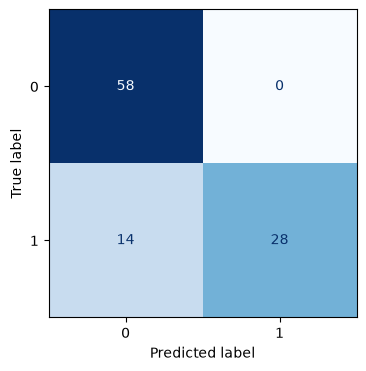

In [25]:
disp=ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
fig, ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)


In [26]:
def plot_decision_boundary(X_tr, X_ts, wts):
    fig, ax =plt.subplots()
    dm= 0.01
    margin= 10*dm
    x_min, x_max= X_tr[:,0].min() - margin, X_tr[:, 0].max() + margin
    y_min, y_max= X_tr[:,1].min() - margin, X_tr[:, 1].max() + margin

    xx, yy= np.meshgrid(np.arange(x_min, x_max, dm), 
                        np.arange(y_min, y_max, dm))
    XX= np.c_[xx.ravel(), yy.ravel()]
    XX= np.hstack((XX, np.ones((XX.shape[0],1))))
    y_pred=[]
    for row in XX:
        a= predict(row, wts)
        y_pred.append(a)
    Z=np.array(y_pred).reshape(xx.shape)
    ax.contourf(xx,yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:, 0], X_tr[:,1], c = X_tr[:, 2],
               s=30, edgecolors='k', cmap='coolwarm')
    ax.scatter(X_ts[:, 0], X_ts[:,1], c = X_ts[:, 2],
               s=30, marker= '*', edgecolors='k', cmap=plt.cm.seismic)

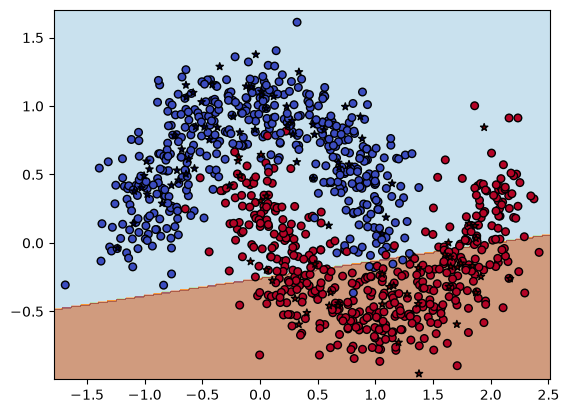

In [27]:
plot_decision_boundary(data_train, data_test, weights)

In [38]:
def fn_sigmoid(z):
    return 1/ (1+ np.exp(-z))

In [39]:
fn_sigmoid(np.asarray([-np.inf,-1,0,+1,np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

In [40]:
def predict(row: np.ndarray, wgts: np.ndarray):
    '''
    row: one sample of data
    wgts: Weight of the model
    '''
    z=wgts[0]

    for i in range(len(row)-1):
        z+= wgts[i+1]* row[i] # Aggrigation function
    return fn_sigmoid(z)# sample activation

In [41]:
weight=np.array([0.1, 2.0, 1.0])

display(df.loc[0])
predict(df.loc[0].values,weight)

A         0.906340
B         0.902676
Target    0.000000
Name: 0, dtype: float64

np.float64(0.9434999754763397)

In [42]:
rng.standard_normal(data_train.shape[1]),rng.standard_normal(data_train.shape[1]),rng.standard_normal(data_train.shape[1])

(array([ 0.48004708, -1.77052794,  1.09664929]),
 array([ 0.27218775,  1.35652183, -0.71046344]),
 array([-2.09447365, -1.36959015, -0.24259698]))

In [46]:
def train_weights(train: np.ndarray, alpha: float, n_epochs: int):
    errors=[] # colledt all errors
    weights=rng.standard_normal(train.shape[1])# random generation
    m=train.shape[0] # num samples

    for epoch in range(n_epochs):
        sum_error=0.0
        for row in train:
            a=predict(row,weights)
            error =-row[-1]*np.log(a)-((1-row[-1])*np.log(1-a))
            dz=a-row[-1]# this is (dz=a-y)
            error =prediction -row[-1] 
            weights[0]=weights[0]- alpha*dz
            for i in range(len(row)-1):
                weights[i+1]= weights[i+1]- alpha*dz *row[i]
        errors.append(sum_error/m)
        if epoch%10==0:
            print(f'Epoch {epoch:3d}: Loss={errors[-1]:4f}')
    return errors, weights

In [47]:
errors,weights=train_weights(data_train,ALPHA,EPOCHS)
display(weights)
errors

Epoch   0: Loss=0.000000
Epoch  10: Loss=0.000000
Epoch  20: Loss=0.000000
Epoch  30: Loss=0.000000
Epoch  40: Loss=0.000000
Epoch  50: Loss=0.000000
Epoch  60: Loss=0.000000
Epoch  70: Loss=0.000000
Epoch  80: Loss=0.000000
Epoch  90: Loss=0.000000
Epoch 100: Loss=0.000000
Epoch 110: Loss=0.000000
Epoch 120: Loss=0.000000
Epoch 130: Loss=0.000000
Epoch 140: Loss=0.000000
Epoch 150: Loss=0.000000
Epoch 160: Loss=0.000000
Epoch 170: Loss=0.000000
Epoch 180: Loss=0.000000
Epoch 190: Loss=0.000000


array([ 0.42922709,  1.17662849, -4.30810968])

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0

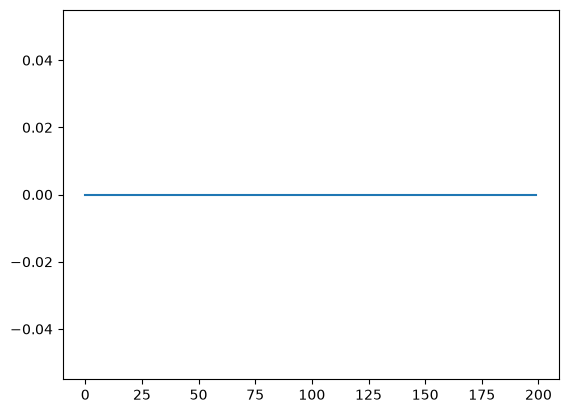

In [48]:
plt.plot(errors)

In [35]:
def plot_decision_boundary(X_tr, X_ts, wts):
    fig, ax =plt.subplots()
    dm= 0.01
    margin= 10*dm
    x_min, x_max= X_tr[:,0].min() - margin, X_tr[:, 0].max() + margin
    y_min, y_max= X_tr[:,1].min() - margin, X_tr[:, 1].max() + margin

    xx, yy= np.meshgrid(np.arange(x_min, x_max, dm), 
                        np.arange(y_min, y_max, dm))
    XX= np.c_[xx.ravel(), yy.ravel()]
    XX= np.hstack((XX, np.ones((XX.shape[0],1))))
    y_pred=[]
    for row in XX:
        a= predict(row, wts)
        y_pred.append(a)
    Z=np.array(y_pred).reshape(xx.shape)
    ax.contourf(xx,yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:, 0], X_tr[:,1], c = X_tr[:, 2],
               s=30, edgecolors='k', cmap='coolwarm')
    ax.scatter(X_ts[:, 0], X_ts[:,1], c = X_ts[:, 2],
               s=30, marker= '*', edgecolors='k', cmap=plt.cm.seismic)